# 03 · Modeling

**Goal:** predict whether someone is in the Low / Medium / High wellbeing group from their social-media habits, compare several models fairly, and interpret the best one.
Previous: [02 Exploration](02_exploratory_analysis.ipynb) · Next: [04 Findings](04_findings_and_recommendations.ipynb)

## Plan
1. Hold back 25% of people as a **test set** that is never used to choose anything.
2. Build a **pipeline** (feature engineering → fill gaps → scale / encode → keep best 20 columns) so every step is learned inside each cross-validation fold: no leakage.
3. Tune six classifiers with **grid search + 5-fold cross-validation**.
4. Pick the winner on cross-validated score (training data only), then report it once on the test set.

## Evaluation metric: macro-F1
* **F1** balances *precision* (when the model says "Low", how often is it right?) and *recall* (of the truly Low people, how many are found?).
* **Macro** averages F1 over the three groups equally, so the hard middle group counts as much as the others.
* Plain accuracy would also work with balanced groups, but macro-F1 additionally penalises a model that ignores a group. A model that always answers "Low" scores a macro-F1 of only about 0.17.
* ROC AUC (how well the model ranks people, 0.5 = chance, 1 = perfect) is reported as a secondary check.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wellbeing.config import Settings
from wellbeing.data import CLASSES, TARGET, add_target, clean, feature_frame, load_raw

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Low": "#d1495b", "Medium": "#edae49", "High": "#2e86ab"}  # one colour per wellbeing group, reused everywhere

# Settings points at the CSV and names every column; the notebooks run from the notebooks/ folder
s = Settings(data_file=Path("../data/social_media_addiction_mental_wellbeing.csv"))
from sklearn.metrics import ConfusionMatrixDisplay

from wellbeing import analysis, modeling
from wellbeing.features import build_preprocessor

df, _ = clean(load_raw(s), s)
df, cuts = add_target(df, s)
X = feature_frame(df, s)
X_train, X_test, y_train, y_test = modeling.split(df, X, s)  # stratified so each split keeps the group mix
print(f"Train: {len(X_train)} people, test: {len(X_test)} people")

Train: 1125 people, test: 375 people


## Feature engineering
Inside the pipeline (see `src/wellbeing/features.py`) three features are added:
* `night_hours`: daily hours × late-night use,
* `notifications_per_hour`: notifications per day ÷ hours,
* `age_group`: age bands.

Then numbers are scaled, categories one-hot encoded, and the 20 most informative columns are kept (ANOVA F-test).

## Tune and compare six models
Models: logistic regression, decision tree, k-nearest neighbours, random forest, linear SVM and RBF SVM, each with its own hyper-parameter grid (`modeling.candidates`). A "baseline" that always predicts the majority group is the bar to beat. This takes under a minute.

In [2]:
tuned = modeling.tune_all(X_train, y_train, X_test, y_test, s)

rows = []
for r in tuned["results"]:
    rows.append({
        "model": r["name"], "cv macro-F1": r["cv_f1_macro"], "cv std": r.get("cv_f1_std"),
        "test macro-F1": r["test"]["f1_macro"], "test accuracy": r["test"]["accuracy"],
        "test ROC AUC": r["test"].get("roc_auc_ovr"), "best hyper-parameters": r["best_params"],
    })
results = pd.DataFrame(rows).sort_values("cv macro-F1", ascending=False)
results

,model,cv macro-F1,cv std,test macro-F1,test accuracy,test ROC AUC,best hyper-parameters
1,Logistic regression,0.6593,0.0391,0.6527,0.6533,0.8382,{'C': 10}
5,SVM (linear kernel),0.6524,0.0214,0.6505,0.6507,NaN,{'C': 1}
6,SVM (Gaussian / RBF kernel),0.6457,0.0443,0.6464,0.6507,NaN,"{'C': 0.5, 'gamma': 0.03}"
4,Random forest,0.6062,0.0269,0.5430,0.5547,0.7517,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
3,K-nearest neighbours,0.5707,0.0193,0.5471,0.5600,0.7342,"{'n_neighbors': 31, 'weights': 'distance'}"
2,Decision tree,0.5053,0.0367,0.4646,0.4693,0.6653,"{'criterion': 'gini', 'max_depth': None, 'min_..."
0,Baseline (always the majority class),NaN,NaN,0.1755,0.3573,NaN,{}


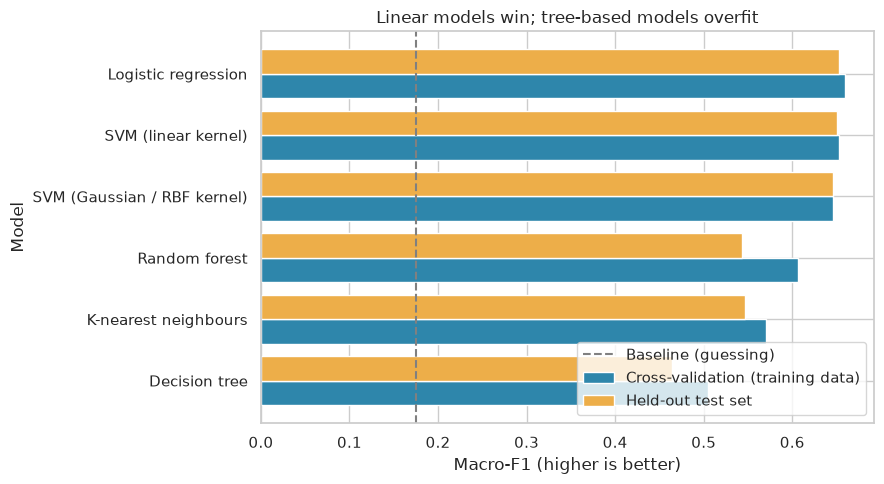

In [3]:
plot = results.dropna(subset=["cv macro-F1"]).sort_values("cv macro-F1")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(plot))
ax.barh(y - 0.2, plot["cv macro-F1"], height=0.4, label="Cross-validation (training data)", color="#2e86ab")
ax.barh(y + 0.2, plot["test macro-F1"], height=0.4, label="Held-out test set", color="#edae49")
ax.set_yticks(y)
ax.set_yticklabels(plot["model"])
ax.axvline(results.loc[results["model"].str.startswith("Baseline"), "test macro-F1"].iloc[0], color="grey", ls="--", label="Baseline (guessing)")
ax.set_xlabel("Macro-F1 (higher is better)")
ax.set_ylabel("Model")
ax.set_title("Linear models win; tree-based models overfit")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [4]:
best_key = tuned["best_key"]
best = next(r for r in tuned["results"] if r["key"] == best_key)
print(f"Winner (highest cross-validated macro-F1): {best['name']} with {best['best_params']}")
print(f"CV macro-F1 {best['cv_f1_macro']:.3f} ± {best['cv_f1_std']:.3f}  →  test macro-F1 {best['test']['f1_macro']:.3f}, ROC AUC {best['test']['roc_auc_ovr']:.3f}")

Winner (highest cross-validated macro-F1): Logistic regression with {'C': 10}
CV macro-F1 0.659 ± 0.039  →  test macro-F1 0.653, ROC AUC 0.838


**Interpretation.**
* The winner is **logistic regression**. SVMs are nearly tied; the flexible tree-based models (decision tree, random forest) and KNN do clearly *worse* on unseen data. The signal is mostly smooth and roughly linear, so extra flexibility only fits noise.
* Cross-validation and test scores agree (≈0.65), so the result is not an accident of one split.
* A macro-F1 near 0.65 against 0.17 for guessing means the model is genuinely useful, but wrong about one person in three: wellbeing has many causes that a social-media survey cannot see.

### Where does the model make mistakes?

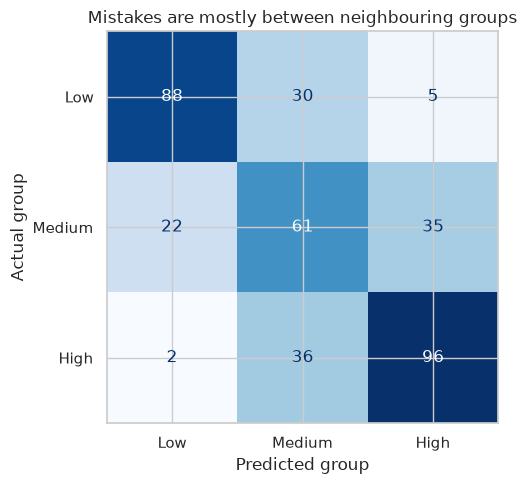

,class,precision,recall,f1,support
0,Low,0.786,0.715,0.749,123
1,Medium,0.480,0.517,0.498,118
2,High,0.706,0.716,0.711,134


In [5]:
best_model = tuned["fitted"][best_key].best_estimator_
pred = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASSES, cmap="Blues", ax=ax, colorbar=False)
ax.set_xlabel("Predicted group")
ax.set_ylabel("Actual group")
ax.set_title("Mistakes are mostly between neighbouring groups")
plt.tight_layout()
plt.show()
pd.DataFrame(modeling.class_report(y_test, pred))

Almost all errors are between *adjacent* groups (Low↔Medium, Medium↔High). Medium is hardest, as expected for a middle group. Confusing Low with High is rare.

## Which inputs matter most? (permutation importance)
Each input is shuffled in turn; the bigger the drop in macro-F1, the more the model relied on it.

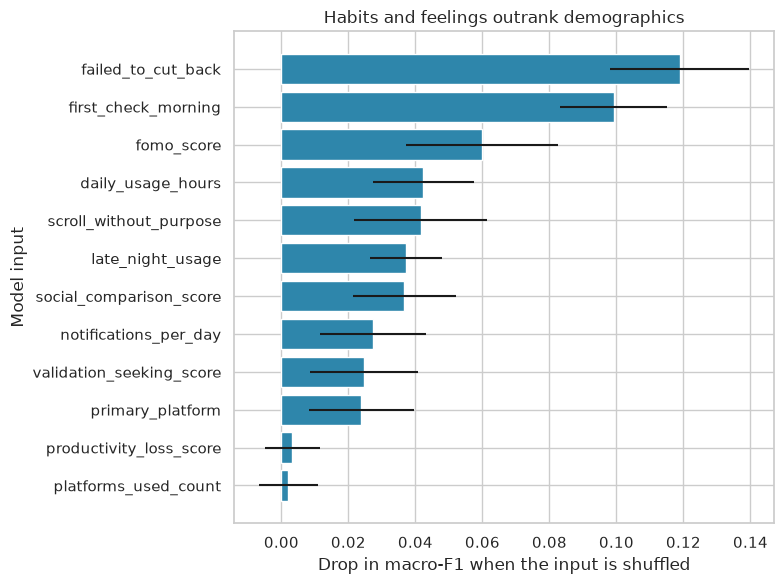

In [6]:
imp = pd.DataFrame(analysis.importance(best_model, X_test, y_test, s))
top = imp.head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#2e86ab")
ax.set_xlabel("Drop in macro-F1 when the input is shuffled")
ax.set_ylabel("Model input")
ax.set_title("Habits and feelings outrank demographics")
plt.tight_layout()
plt.show()

Failing to cut back, checking within minutes of waking and FOMO lead, followed by daily hours and late-night use. Age, gender and occupation add little.

## Check: does adding mental-state measures help?
Anxiety, depression, loneliness, self-esteem and sleep quality were left out because they *measure* wellbeing. To see how much they would add, we refit the same model with them included.

In [7]:
Xm = feature_frame(df, s, mediators=True)
Xm_train, Xm_test = Xm.loc[X_train.index], Xm.loc[X_test.index]
est = modeling.candidates(s)[best_key][0]
mpipe = modeling.make_pipeline(Xm_train, est, s).set_params(**{f"model__{k}": v for k, v in best["best_params"].items()})
mpipe.fit(Xm_train, y_train)
with_med = modeling.metrics(y_test, mpipe.predict(Xm_test))
pd.DataFrame({"habits only (main model)": modeling.metrics(y_test, pred), "habits + mental-state measures": with_med}).loc[["accuracy", "f1_macro"]]

,habits only (main model),habits + mental-state measures
accuracy,0.6533,0.7200
f1_macro,0.6527,0.7135


A modest gain (≈0.65 → ≈0.71): the mental-state measures are informative but circular, so the habits-only model is the right one to answer our question.

## Decision-threshold tuning (tried, not adopted)
We also tried re-weighting the class probabilities to raise macro-F1, searching the weights only on out-of-fold training predictions.

In [8]:
thr, weights, _ = modeling.tune_thresholds(X_train, y_train, X_test, y_test, best_key, best["best_params"], s)
print(f"Out-of-fold macro-F1: {thr['oof_f1_default']:.3f} default → {thr['oof_f1_tuned']:.3f} tuned")
print(f"Test macro-F1:        {thr['test_default']['f1_macro']:.3f} default → {thr['test_tuned']['f1_macro']:.3f} tuned")
print("Adopted:", thr["adopted"])

Out-of-fold macro-F1: 0.660 default → 0.670 tuned
Test macro-F1:        0.653 default → 0.645 tuned
Adopted: False


The out-of-fold gain is about one point and **does not carry over to the test set**, so we keep the default threshold. A change that doesn't generalise isn't an improvement.

## Summary
| | |
|---|---|
| Chosen model | Logistic regression (C = 10) |
| Metric | Macro-F1, chosen because all three groups matter equally |
| Cross-validated | ≈ 0.66 ± 0.04 |
| Test | macro-F1 ≈ 0.65, accuracy ≈ 0.65, ROC AUC ≈ 0.84 (baseline 0.17) |

Next: turn this into plain-language findings → [04 Findings](04_findings_and_recommendations.ipynb)